#### Utilisation de CLIP (Contrastive Language–Image Pre-training) avec la bibliothèque open_clip pour transformer un texte et une image en vecteurs numériques (embeddings).

In [ ]:
import torch # torch effectue les calculs avec pytorch
import open_clip  # Permet d'utiliser le model CLIP
from PIL import Image # Permet d'ouvrir  et de manipuler  des images
import numpy 

# Choisir le materiel de calcul cuda . Check si le laptop dispose d'un  GPUNVIDIA compatible avec cuda
DEVICE = "cuda" if torch.cuda.is_available() else "cpu" # Si CUDA dispo , Use  GPU(CUDA) Sinon use processeur (CPU)

# Choisis du modèle qui va apprendre à représenter les images et les textes dans un espace vectoriel commun
MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"

# Charger le modèle et le prétraitement des images
model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME,
    pretrained=PRETRAINED
)
model = model.to(DEVICE).eval()

# Charger le tokenizer
tokenizer = open_clip.get_tokenizer(MODEL_NAME)

# --- Préparer le texte ---
texte = "Un chat sur un canapé"
tokens = tokenizer([texte]).to(DEVICE)

# --- Préparer l'image ---
with Image.open("architecture_transformer.png") as image:
    tenseur_image = preprocess(image.convert("RGB")) # Convertit l'image en RGB (rouge, vert, bleu).

# Ajouter la dimension batch : [3, H, W] → [1, 3, H, W]
tenseur_image = tenseur_image.unsqueeze(0).to(DEVICE)

# --- Encoder le texte et l'image! Avec inference mode pour ne pas calculer les gradients dans cette fonction
with torch.inference_mode():
    vecteur_texte = model.encode_text(tokens) # Pour avec le vecteur texte
    vecteur_image = model.encode_image(tenseur_image) # Pour le vecteur image

    # IL faut faire la normalisation avans de le stock dans la base vectoriel
    # Normaliser les embeddings 
    vecteur_texte = vecteur_texte / vecteur_texte.norm(dim=-1, keepdim=True)
    vecteur_image = vecteur_image / vecteur_image.norm(dim=-1, keepdim=True)

# Convertir en listes Python utilisables par ChromaDB
# Convertir les tenseurs en listes Python
vecteur_texte = vecteur_texte[0].cpu().tolist()
vecteur_image = vecteur_image[0].cpu().tolist()

print("Dimension texte :", len(vecteur_texte))  # 512
print("Dimension image :", len(vecteur_image))  # 512

print("Embedding texte (5 premières valeurs) :", vecteur_texte[:5])
print("Embedding image (5 premières valeurs) :", vecteur_image[:5])

Dimension texte : 512
Dimension image : 512
Embedding texte (5 premières valeurs) : [0.02338835783302784, 0.018530473113059998, -0.002719964599236846, 0.09746265411376953, -0.017327917739748955]
Embedding image (5 premières valeurs) : [0.021040016785264015, -0.08871836960315704, 0.01596060022711754, 0.012357422150671482, -0.09283776581287384]


## Indiquer le fichier PDF

## Encoder un texte et une image avec CLIP

In [ ]:
from pathlib import Path
import pymupdf

PDF_PATH = Path("./pdfs/attention_is_all_you_need.pdf")

# Save the result dans le dossier resultats_pdf
OUTPUT_DIR = Path("resultats_pdf")
TEXT_DIR = OUTPUT_DIR / "textes"
IMAGE_DIR = OUTPUT_DIR / "images"

if not PDF_PATH.is_file():
    raise FileNotFoundError(f"Fichier introuvable : {PDF_PATH.resolve()}")

TEXT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

print(f"PDF : {PDF_PATH.resolve()}")
print(f"Résultats : {OUTPUT_DIR.resolve()}")

PDF : /home/superrama/rag_multimodal/pdfs/attention_is_all_you_need.pdf
Résultats : /home/superrama/rag_multimodal/resultats_pdf


## Extraire le texte et les images

In [23]:
import pymupdf
textes = []
nombre_images = 0
pages_sans_texte = []

with pymupdf.open(PDF_PATH) as document:
    nombre_pages = len(document)

    for numero_page, page in enumerate(document, start=1):
        # ---- Extraction du texte ----
        texte = page.get_text("text", sort=True)

        fichier_texte = TEXT_DIR / f"page_{numero_page:03d}.txt"
        fichier_texte.write_text(texte, encoding="utf-8")

        textes.append(f"===== PAGE {numero_page} =====\n\n{texte}")

        if not texte.strip():
            pages_sans_texte.append(numero_page)

        # ---- Extraction des images intégrées ----
        # Éviter d'extraire plusieurs fois la même image sur une page.
        images_vues = set()

        for image_info in page.get_images(full=True):
            xref = image_info[0]

            if xref in images_vues:
                continue

            images_vues.add(xref)

            try:
                image = document.extract_image(xref)

                if not image:
                    print(f"Image non extractible : page {numero_page}, xref {xref}")
                    continue

                extension = image["ext"]
                fichier_image = (
                    IMAGE_DIR
                    / f"page_{numero_page:03d}_image_{xref}.{extension}"
                )
                fichier_image.write_bytes(image["image"])

                nombre_images += 1

            except Exception as erreur:
                print(
                    f"Erreur d'extraction : page {numero_page}, "
                    f"image {xref} : {erreur}"
                )

# Enregistrer le texte de tout le document.
(OUTPUT_DIR / "texte_complet.txt").write_text(
    "\n\n".join(textes),
    encoding="utf-8"
)

print(f"Pages traitées : {nombre_pages}")
print(f"Images enregistrées : {nombre_images}")

if pages_sans_texte:
    print("Pages sans texte détectable :", pages_sans_texte)
    print("Si elles contiennent du texte scanné, utilisez l'OCR ci-dessous.")

Pages traitées : 11
Images enregistrées : 3


## Afficher un aperçu des résultats

APERÇU DU TEXTE

===== PAGE 1 =====

             Attention Is All You Need





     Ashish Vaswani∗      Noam Shazeer∗       Niki Parmar∗     Jakob Uszkoreit∗
      Google Brain          Google Brain       Google Research     Google Research
  avaswani@google.com   noam@google.com   nikip@google.com   usz@google.com


        Llion Jones∗          Aidan N. Gomez∗†            Łukasz Kaiser∗
     Google Research          University of Toronto              Google Brain
    llion@google.com     aidan@cs.toronto.edu     lukaszkaiser@google.com


                                               Illia Polosukhin∗‡
                         illia.polosukhin@gmail.com



                                Abstract

       The dominant sequence transduction models are based on complex recurrent or
        convolutional neural networks that include an encoder and a decoder. The best
        performing models also connect the encoder and decoder through an attention
       mechanism. We propose a new 

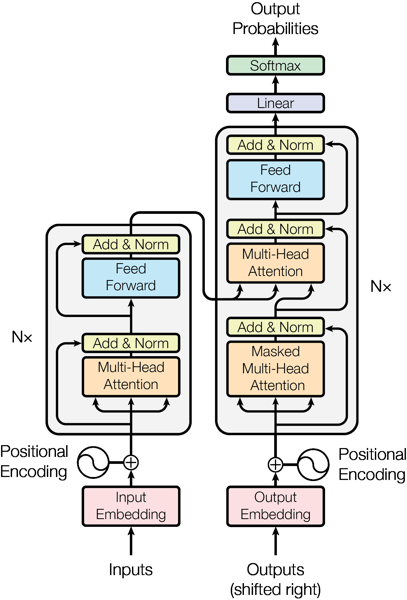

page_004_image_102.png


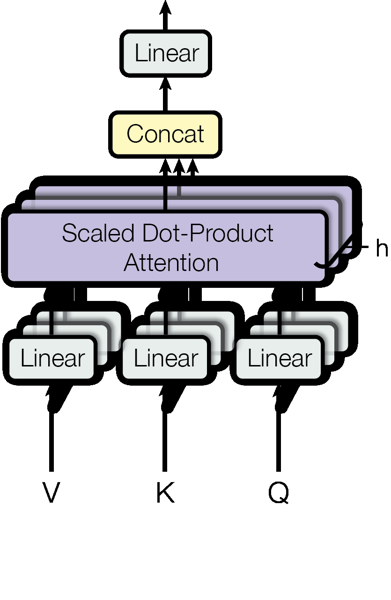

page_004_image_104.png


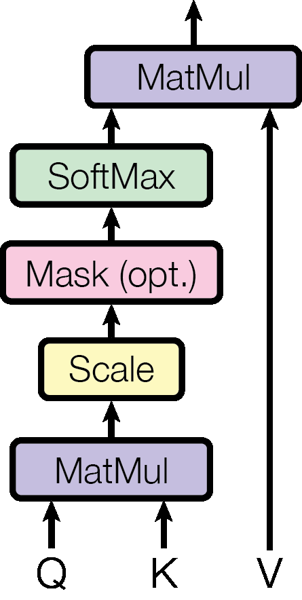

In [24]:
from PIL import Image
from IPython.display import display

texte_complet = (OUTPUT_DIR / "texte_complet.txt").read_text(
    encoding="utf-8"
)

print("APERÇU DU TEXTE\n")
print(texte_complet[:2000])

print("\nAPERÇU DES IMAGES\n")

# 
for fichier in sorted(IMAGE_DIR.iterdir())[:5]:
    print(fichier.name)

    with Image.open(fichier) as image:
        apercu = image.copy()
        apercu.thumbnail((600, 600))
        display(apercu)

## Charger le modèle et ouvrir ChromaDB

In [25]:
from pathlib import Path
import hashlib
import re

import torch
import open_clip
import chromadb

from PIL import Image
from open_clip.tokenizer import SimpleTokenizer

# Dossiers produits par les cellules d'extraction
OUTPUT_DIR = Path("resultats_pdf")
TEXT_DIR = OUTPUT_DIR / "textes"
IMAGE_DIR = OUTPUT_DIR / "images"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"

model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME,
    pretrained=PRETRAINED
)

model = model.to(DEVICE).eval()
tokenizer = open_clip.get_tokenizer(MODEL_NAME)

# Tokeniseur BPE adapté au modèle CLIP choisi
bpe = SimpleTokenizer()

# Base persistante sur disque
client = chromadb.PersistentClient(path="chroma_pdf")

collection = client.get_or_create_collection(
    name="pdf_clip_vit_b32",
    embedding_function=None,  # Les embeddings sont calculés par notre code
    metadata={"hnsw:space": "cosine"}
)

print("Appareil :", DEVICE)
print("Éléments déjà présents :", collection.count())

Appareil : cpu
Éléments déjà présents : 0


## Préparer le découpage et les embeddings

In [ ]:
# 
def decouper_texte(texte, taille=60, chevauchement=10):
    """Découper le texte en fragments courts adaptés à CLIP."""
    if not 0 <= chevauchement < taille:
        raise ValueError("Le chevauchement doit être inférieur à la taille.")

    tokens = bpe.encode(texte)

    for debut in range(0, len(tokens), taille - chevauchement):
        fragment = bpe.decode(tokens[debut:debut + taille]).strip()

        if fragment:
            yield fragment

        if debut + taille >= len(tokens):
            break

### Une autre solution en utilisant RecursiveCharacterTextSplitter de langchain

In [27]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

def decouper_texte_V2(texte, taille=60, chevauchement=10):
    """Découper le texte en privilégiant les limites naturelles."""
    if not 0 <= chevauchement < taille:
        raise ValueError("Le chevauchement doit être inférieur à la taille.")

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=taille,
        chunk_overlap=chevauchement,
        length_function=lambda texte: len(bpe.encode(texte)),
        separators=["\n\n", "\n", " ", ""],
        strip_whitespace=True,
    )

    yield from splitter.split_text(texte)

## Encodage des textes en vecteurs avec CLIP

In [28]:
import torch
@torch.inference_mode()
def encoder_textes(textes):
    tokens = tokenizer(textes).to(DEVICE)
    vecteurs = model.encode_text(tokens).float()

    vecteurs = vecteurs / vecteurs.norm(
        dim=-1, keepdim=True
    ).clamp_min(1e-12)

    return vecteurs.cpu().tolist()

## Encodage d’une image en vecteur avec CLIP

In [29]:
@torch.inference_mode()
def encoder_image(chemin):
    with Image.open(chemin) as image:
        tenseur = preprocess(image.convert("RGB"))

    tenseur = tenseur.unsqueeze(0).to(DEVICE)
    vecteur = model.encode_image(tenseur).float()

    vecteur = vecteur / vecteur.norm(
        dim=-1, keepdim=True
    ).clamp_min(1e-12)

    return vecteur.cpu().tolist()[0]

## Indexation des textes du PDF dans ChromaDB

Chaque fragment possède :

- son embedding ;
- son texte ;
- le numéro de page ;
- l’identifiant du PDF ;
- le chemin du fichier source.

In [30]:
from pathlib import Path
import hashlib


PDF_PATH = Path("./pdfs/attention_is_all_you_need.pdf")

# PDF_PATH provient des cellules précédentes
PDF_PATH = Path(PDF_PATH)

# Identifiant lié au contenu du PDF
document_id = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()[:24]

# Supprimer l'ancienne version de l'index de ce PDF.
# Cela évite les fragments obsolètes après une nouvelle extraction.
collection.delete(where={"document_id": document_id})

ids = []
documents = []
metadatas = []

for fichier in sorted(TEXT_DIR.glob("page_*.txt")):
    texte = fichier.read_text(encoding="utf-8")
    page = numero_page(fichier)

    for index, fragment in enumerate(decouper_texte(texte)):
        ids.append(f"{document_id}:texte:{page}:{index}")
        documents.append(fragment)

        metadatas.append({
            "type": "texte",
            "document_id": document_id,
            "pdf": PDF_PATH.name,
            "page": page,
            "fragment": index,
            "source": str(fichier.resolve())
        })

# Indexation par lots
TAILLE_LOT = 64

for debut in range(0, len(documents), TAILLE_LOT):
    fin = debut + TAILLE_LOT
    lot = documents[debut:fin]

    collection.upsert(
        ids=ids[debut:fin],
        documents=lot,
        metadatas=metadatas[debut:fin],
        embeddings=encoder_textes(lot)
    )

print(f"{len(documents)} fragments de texte indexés.")

TypeError: 'int' object is not callable

## Indexer les images dans la même collection
Le champ documents des images est seulement une description technique : l’embedding est bien calculé à partir des pixels, et non du nom du fichier.

In [ ]:
# 
extensions = {".png", ".jpg", ".jpeg", ".webp", ".bmp", ".tif", ".tiff", ".jp2"}
nombre_images_indexees = 0

for fichier in sorted(IMAGE_DIR.iterdir()):
    if not fichier.is_file() or fichier.suffix.lower() not in extensions:
        continue

    try:
        vecteur = encoder_image(fichier)

        collection.upsert(
            ids=[f"{document_id}:image:{fichier.name}"],
            embeddings=[vecteur],
            documents=[f"Image extraite du PDF : {fichier.name}"],
            metadatas=[{
                "type": "image",
                "document_id": document_id,
                "pdf": PDF_PATH.name,
                "page": numero_page(fichier),
                "source": str(fichier.resolve())
            }]
        )

        nombre_images_indexees += 1

    except Exception as erreur:
        print(f"Image ignorée : {fichier.name} — {erreur}")

print(f"{nombre_images_indexees} images indexées.")
print(f"Total dans ChromaDB : {collection.count()} éléments.")

## Recherche multimodale dans ChromaDB: Rechercher avec du texte ou une image

In [ ]:
def rechercher(texte=None, image=None, type_resultat=None, k=5):
    """
    Fournir soit un texte, soit un chemin d'image.
    type_resultat : None, "texte" ou "image".
    """
    if (texte is None) == (image is None):
        raise ValueError("Fournissez soit un texte, soit une image.")

    if type_resultat not in (None, "texte", "image"):
        raise ValueError("type_resultat doit être 'texte', 'image' ou None.")

    if k < 1:
        raise ValueError("k doit être supérieur ou égal à 1.")

    total = collection.count()
    if total == 0:
        raise ValueError("La collection est vide.")

    vecteur = (
        encoder_textes([texte])[0]
        if texte is not None
        else encoder_image(image)
    )

    options = {}
    if type_resultat is not None:
        options["where"] = {"type": type_resultat}

    return collection.query(
        query_embeddings=[vecteur],
        n_results=min(k, total),
        include=["documents", "metadatas", "distances"],
        **options
    )

## Affichage des résultats de recherche dans le notebook

In [ ]:
from IPython.display import display

def afficher_resultats(resultats):
    for rang, (document, metadata, distance) in enumerate(
        zip(
            resultats["documents"][0],
            resultats["metadatas"][0],
            resultats["distances"][0]
        ),
        start=1
    ):
        print(
            f"\n{rang}. {metadata['type'].upper()} "
            f"| PDF : {metadata['pdf']} "
            f"| Page : {metadata['page']} "
            f"| Similarité cosinus : {1 - distance:.3f}"
        )

        if metadata["type"] == "image":
            chemin = Path(metadata["source"])

            if chemin.is_file():
                with Image.open(chemin) as image:
                    apercu = image.convert("RGB")
                    apercu.thumbnail((600, 450))
                    display(apercu)
            else:
                print("Fichier image introuvable :", chemin)
        else:
            print(document)

**Exemple A — rechercher du texte et des images**

Avec ce modèle, essayez de préférence une requête en anglais :

**Exemple C — rechercher à partir d’une image**

In [ ]:
resultats = rechercher(
    image="./resultats_pdf/images/page_003_image_94.png",
    k=5
)

afficher_resultats(resultats)